In [1]:
import os
from pathlib import Path
import pandas as pd

data_dir = Path('data')
detection_datasets = []

for dataset_dir in data_dir.iterdir():
    if dataset_dir.is_dir():
        txt_files = list(dataset_dir.rglob('*.txt'))
        if len(txt_files) >= 10:
            detection_datasets.append(dataset_dir.name)

print(f"Datasets with 10+ txt files: {detection_datasets}")

Datasets with 10+ txt files: ['augmented.v1i.yolo26', 'cigar.v2i.yolo26', 'cigarette smokers.v5-rsd.yolo26', 'Cigarette Vape Detection.v14i.yolo26', 'CigDet_dataset', 'data_kaggle_smoke_eat_drink_phone', 'DMS - Driver Monitoring System', 'iuhgiu786.v1i.yolo26', 'project11.v1i.yolo26', 'sigara deneme.v2i.yolo26', 'Smoking detection.v2i.yolo26', 'Smoking Detection.v5i.yolo26', 'Smoking v2.v1i.yolo26', 'smoking.v1-smoker1.yolo26', 'smoking26.v1i.yolo26', 'smokingProjec.v1i.yolo26', 'VNTU_Object_Detection_YOLO8S.v8i.yolo26']


In [8]:
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.tif', '.webp', '.gif'}

rows = []
def get_pair_type(path):
    if 'train' in path:
        return 'train'
    if 'val' in path:
        return 'valid'
    if 'test' in path:
        return 'test'
    return 'unk'


for dataset_name in detection_datasets:
    dataset_path = data_dir / dataset_name
    
    txt_files = list(dataset_path.rglob('*.txt'))
    image_files = []
    for ext in image_extensions:
        image_files.extend(dataset_path.rglob(f'*{ext}'))
    
    image_dict = {img.stem: img for img in image_files}
    
    for txt_file in txt_files:
        txt_stem = txt_file.stem
        
        if txt_stem in image_dict:
            img_file = image_dict[txt_stem]
            rows.append({
                'dataset': dataset_name,
                'txt_path': str(txt_file),
                'image_path': str(img_file),
                'image_dir': get_pair_type(str(img_file))
            })

df = pd.DataFrame(rows)
print(f"Total matched pairs: {len(df)}")
df.head()

Total matched pairs: 114096


,dataset,txt_path,image_path,image_dir
0,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000048_j...,data\augmented.v1i.yolo26\test\images\000048_j...,test
1,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000068_j...,data\augmented.v1i.yolo26\test\images\000068_j...,test
2,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000119_j...,data\augmented.v1i.yolo26\test\images\000119_j...,test
3,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000120_j...,data\augmented.v1i.yolo26\test\images\000120_j...,test
4,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000149_j...,data\augmented.v1i.yolo26\test\images\000149_j...,test


In [6]:
len(detection_datasets)

17

In [9]:
df.image_dir.unique()

array(['test', 'train', 'valid'], dtype=object)

In [10]:
result = (
    df
    .groupby(["dataset", "image_dir"])
    .size()
    .unstack(fill_value=0)
    .assign(total=lambda x: x.sum(axis=1))
    .reset_index()
)
result

image_dir,dataset,test,train,valid,total
0,CigDet_dataset,111,446,0,557
1,Cigarette Vape Detection.v14i.yolo26,577,12111,1158,13846
2,DMS - Driver Monitoring System,37,780,74,891
3,Smoking Detection.v5i.yolo26,732,16758,740,18230
4,Smoking detection.v2i.yolo26,133,2700,249,3082
5,Smoking v2.v1i.yolo26,120,901,196,1217
6,VNTU_Object_Detection_YOLO8S.v8i.yolo26,197,1802,497,2496
7,augmented.v1i.yolo26,207,1455,416,2078
8,cigar.v2i.yolo26,74,1305,72,1451
9,cigarette smokers.v5-rsd.yolo26,838,6719,844,8401


In [43]:
import matplotlib.pyplot as plt
from PIL import Image
import matplotlib.patches as patches

def visualize_yolo_sample(row, class_names=None):
    img = Image.open(row.image_path).convert("RGB")
    w, h = img.size
    img_area = w * h

    fig, ax = plt.subplots(1, figsize=(10, 10))
    ax.imshow(img)

    with open(row.txt_path) as f:
        for i, line in enumerate(f, 1):
            cls, cx, cy, bw, bh = map(float, line.strip().split())
            x = (cx - bw / 2) * w
            y = (cy - bh / 2) * h
            bw_px = bw * w
            bh_px = bh * h

            box_area_px = bw_px * bh_px
            box_area_rel = box_area_px / img_area

            print(
                f"box {i}: "
                f"class={int(cls)} "
                f"area_px={box_area_px:.1f} "
                f"area_rel={box_area_rel:.4f}"
            )

            rect = patches.Rectangle(
                (x, y), bw_px, bh_px,
                linewidth=2, edgecolor="red", facecolor="none"
            )
            ax.add_patch(rect)

            label = class_names[int(cls)] if class_names else str(int(cls))
            ax.text(x, y - 5, label, color="red", fontsize=12, backgroundcolor="white")

    ax.axis("off")
    plt.show()

box 1: class=0 area_px=2420.0 area_rel=0.0059


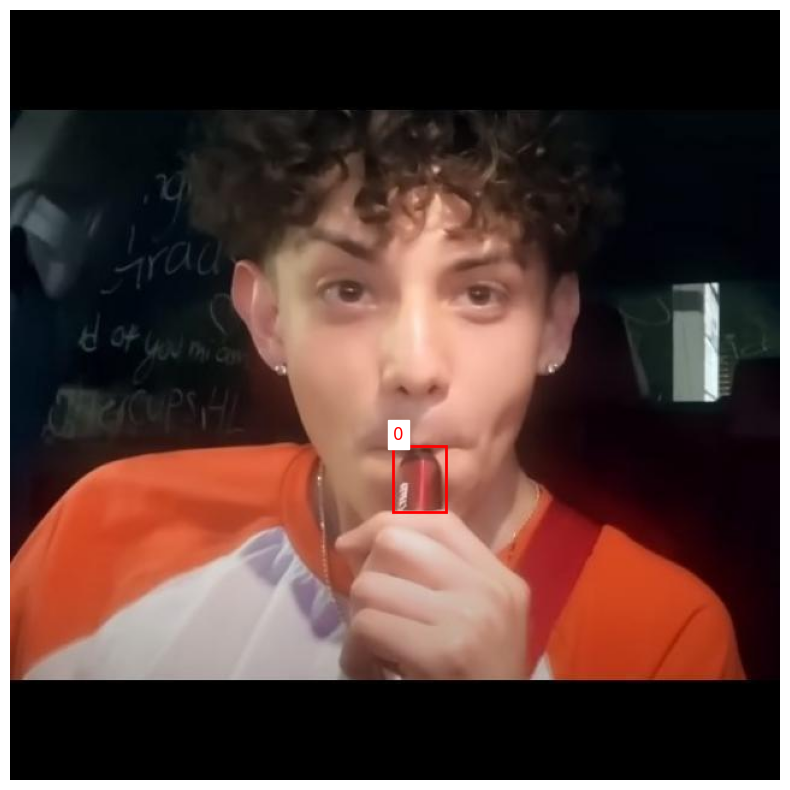

In [51]:
visualize_yolo_sample(df.iloc[10100])

In [54]:
from PIL import Image

def has_small_box(row, thr=0.01):
    img = Image.open(row.image_path)
    w, h = img.size
    img_area = w * h

    with open(row.txt_path) as f:
        for line in f:
            try:
                _, cx, cy, bw, bh = map(float, line.strip().split())
                box_area_rel = (bw * w * bh * h) / img_area
                if box_area_rel <= thr:
                    return True
            except Exception as e:
                pass
    return False


df_small_boxes = df[df.apply(has_small_box, axis=1)].reset_index(drop=True)

In [55]:
df_small_boxes

,dataset,txt_path,image_path,image_dir
0,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000048_j...,data\augmented.v1i.yolo26\test\images\000048_j...,test
1,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000068_j...,data\augmented.v1i.yolo26\test\images\000068_j...,test
2,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000119_j...,data\augmented.v1i.yolo26\test\images\000119_j...,test
3,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000281_j...,data\augmented.v1i.yolo26\test\images\000281_j...,test
4,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000291_j...,data\augmented.v1i.yolo26\test\images\000291_j...,test
...,...,...,...,...
34700,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid
34701,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid
34702,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid
34703,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid


In [57]:
df.to_csv('all_detection_datasets', index = False)
df_small_boxes.to_csv('small_box_detection_datasets', index = False)

box 1: class=1 area_px=2944.0 area_rel=0.0072


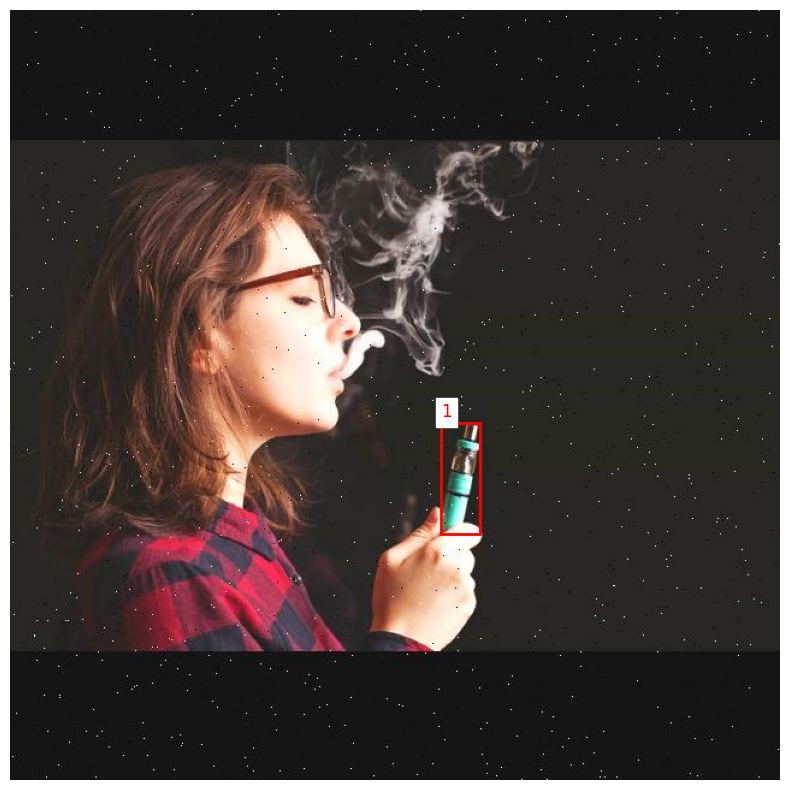

In [79]:
visualize_yolo_sample(df_small_boxes.iloc[10000])

Select even more distant shots: keep only images with a bounding box of at most 0.2% of the frame area (the *micro* subset).

In [107]:
df_micro_boxes = df_small_boxes[
    df_small_boxes.apply(lambda row: has_small_box(row, thr=0.002), axis=1)
].reset_index(drop=True)

In [108]:
df_micro_boxes

,dataset,txt_path,image_path,image_dir
0,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000068_j...,data\augmented.v1i.yolo26\test\images\000068_j...,test
1,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000281_j...,data\augmented.v1i.yolo26\test\images\000281_j...,test
2,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\000291_j...,data\augmented.v1i.yolo26\test\images\000291_j...,test
3,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\013_jpg....,data\augmented.v1i.yolo26\test\images\013_jpg....,test
4,augmented.v1i.yolo26,data\augmented.v1i.yolo26\test\labels\015_jpg....,data\augmented.v1i.yolo26\test\images\015_jpg....,test
...,...,...,...,...
10897,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid
10898,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid
10899,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid
10900,VNTU_Object_Detection_YOLO8S.v8i.yolo26,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,data\VNTU_Object_Detection_YOLO8S.v8i.yolo26\v...,valid


box 1: class=0 area_px=550.0 area_rel=0.0013


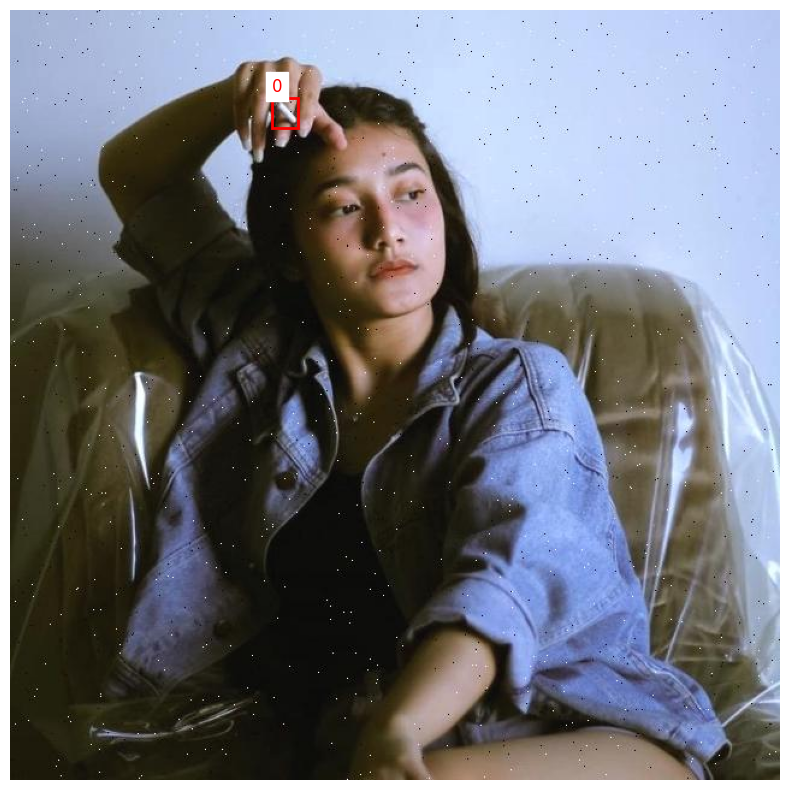

In [111]:
visualize_yolo_sample(df_micro_boxes.iloc[3000])

In [113]:
result = (
    df_micro_boxes
    .groupby(["dataset", "image_dir"])
    .size()
    .unstack(fill_value=0)
    .assign(total=lambda x: x.sum(axis=1))
    .reset_index()
)
result

image_dir,dataset,test,train,valid,total
0,CigDet_dataset,2,3,0,5
1,Cigarette Vape Detection.v14i.yolo26,152,2751,286,3189
2,Smoking Detection.v5i.yolo26,220,1497,81,1798
3,Smoking detection.v2i.yolo26,0,61,5,66
4,Smoking v2.v1i.yolo26,1,15,0,16
5,VNTU_Object_Detection_YOLO8S.v8i.yolo26,21,408,101,530
6,augmented.v1i.yolo26,63,419,119,601
7,cigar.v2i.yolo26,12,190,14,216
8,cigarette smokers.v5-rsd.yolo26,115,798,111,1024
9,data_kaggle_smoke_eat_drink_phone,111,788,222,1121


In [114]:
df_micro_boxes.to_csv('micro_box_detection_datasets', index = False)

In [121]:
import matplotlib.pyplot as plt
from PIL import Image
import matplotlib.patches as patches
from collections import defaultdict

def visualize_classes_per_dataset(df, class_names=None):
    dataset_class_sample = defaultdict(dict)

    for _, row in df.iterrows():
        with open(row.txt_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls = int(float(parts[0]))
                if cls not in dataset_class_sample[row.dataset]:
                    dataset_class_sample[row.dataset][cls] = row

    for dataset, cls_rows in dataset_class_sample.items():
        print(f"\nDataset: {dataset}")

        for cls, row in sorted(cls_rows.items()):
            img = Image.open(row.image_path).convert("RGB")
            w, h = img.size

            fig, ax = plt.subplots(1, figsize=(6, 6))
            ax.imshow(img)

            with open(row.txt_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    c, cx, cy, bw, bh = map(float, parts[:5])
                    if int(c) != cls:
                        continue

                    x = (cx - bw / 2) * w
                    y = (cy - bh / 2) * h
                    bw_px = bw * w
                    bh_px = bh * h

                    rect = patches.Rectangle(
                        (x, y), bw_px, bh_px,
                        linewidth=2, edgecolor="red", facecolor="none"
                    )
                    ax.add_patch(rect)

                    label = class_names[cls] if class_names else str(cls)
                    ax.text(x, y - 5, label, color="red", fontsize=12, backgroundcolor="white")

            ax.set_title(f"{dataset} — class {cls}")
            ax.axis("off")
            plt.show()


Dataset: augmented.v1i.yolo26


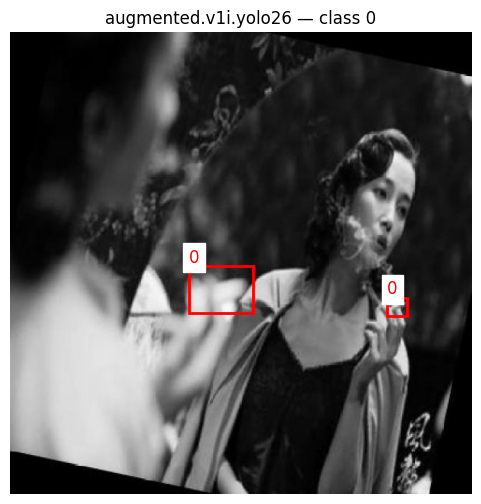


Dataset: cigar.v2i.yolo26


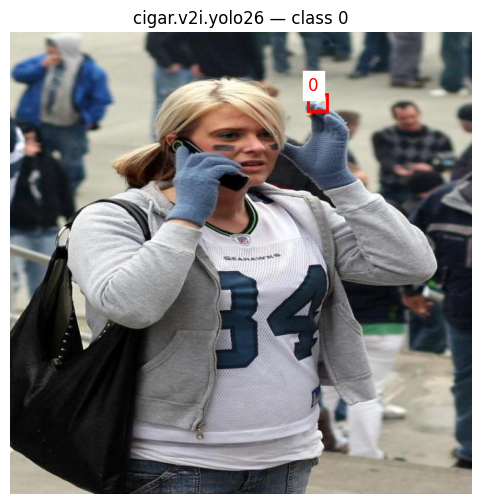

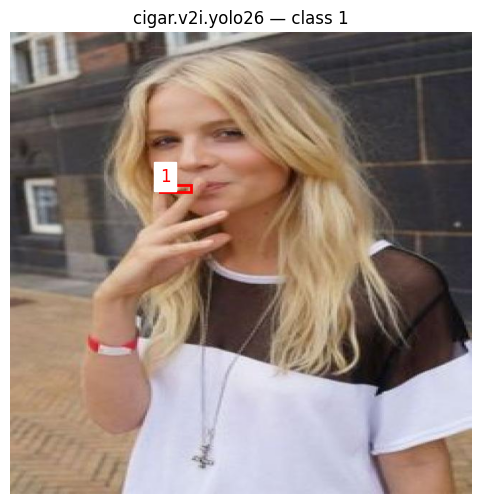


Dataset: cigarette smokers.v5-rsd.yolo26


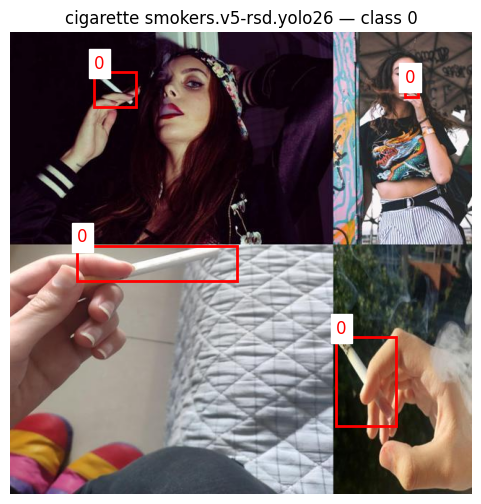


Dataset: Cigarette Vape Detection.v14i.yolo26


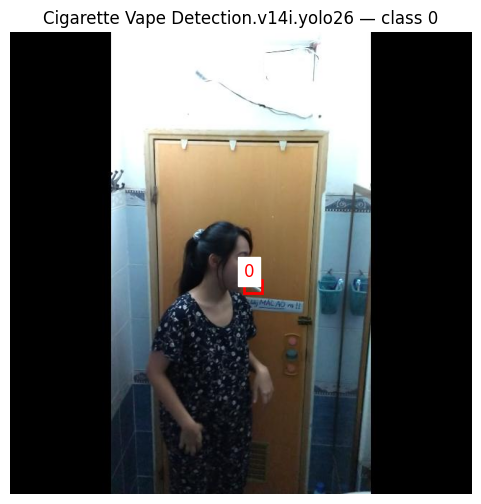

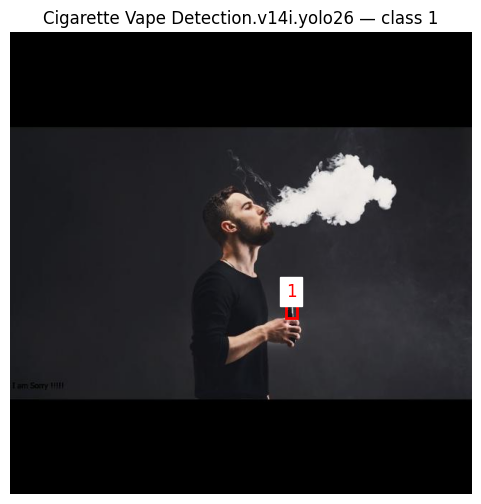


Dataset: CigDet_dataset


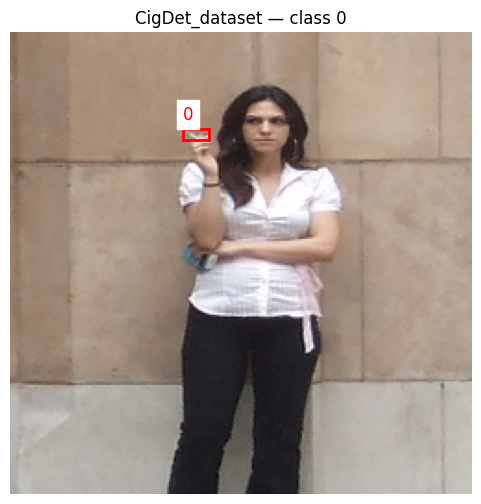


Dataset: data_kaggle_smoke_eat_drink_phone


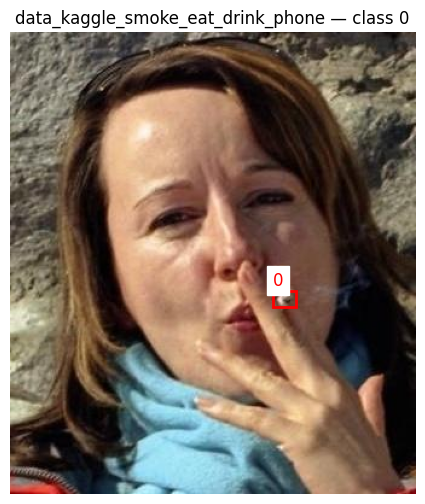

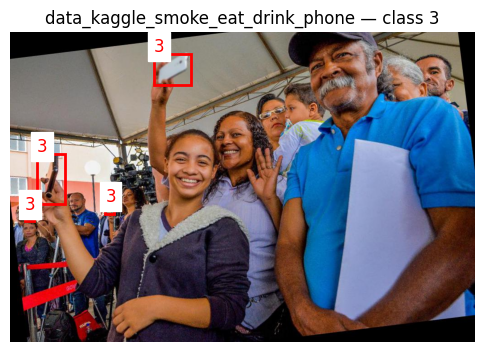


Dataset: iuhgiu786.v1i.yolo26


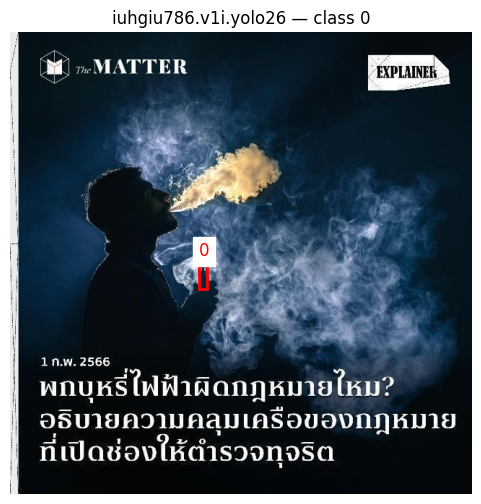

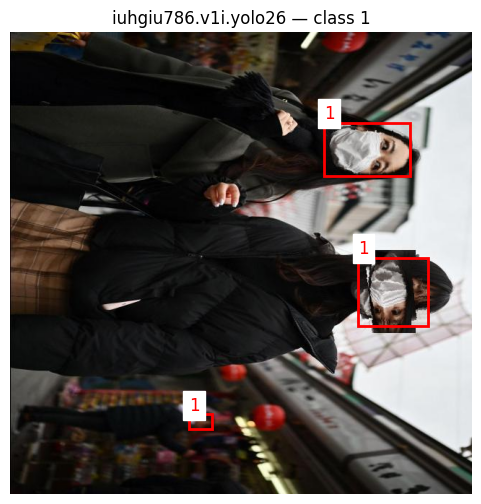


Dataset: project11.v1i.yolo26


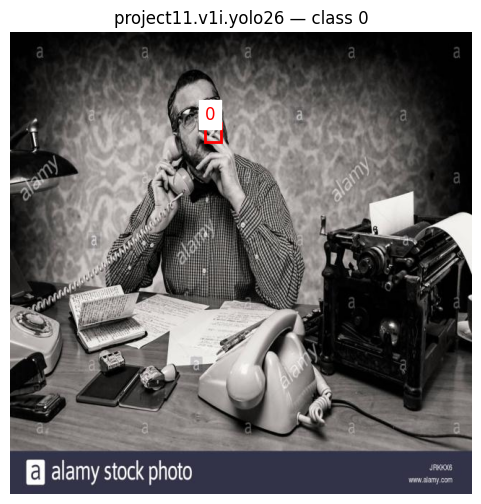


Dataset: sigara deneme.v2i.yolo26


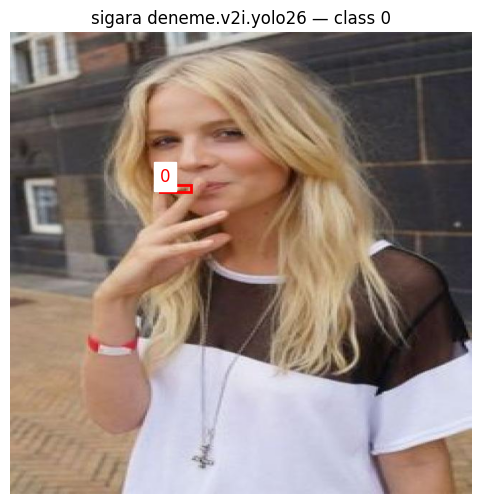


Dataset: Smoking detection.v2i.yolo26


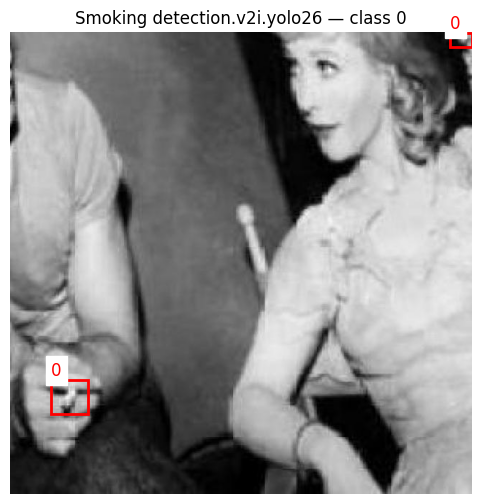


Dataset: Smoking Detection.v5i.yolo26


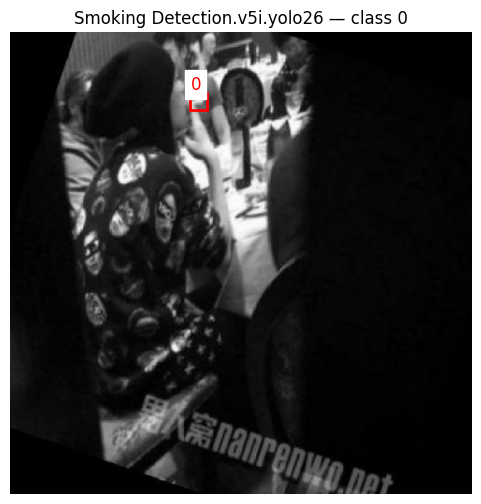


Dataset: Smoking v2.v1i.yolo26


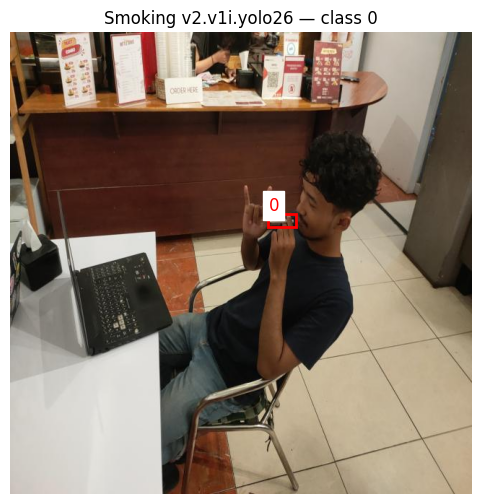


Dataset: smoking.v1-smoker1.yolo26


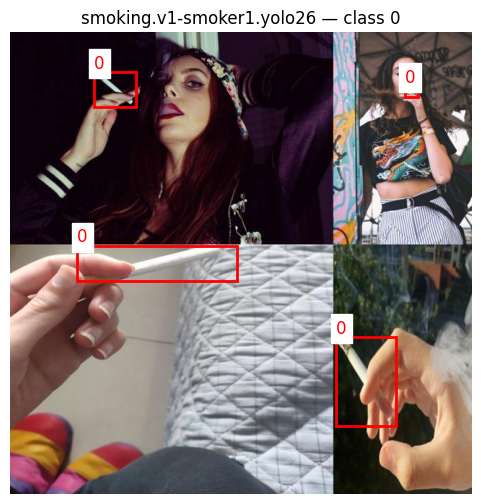


Dataset: smoking26.v1i.yolo26


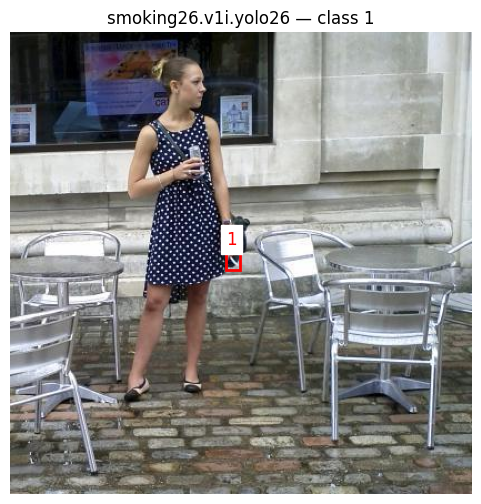


Dataset: smokingProjec.v1i.yolo26


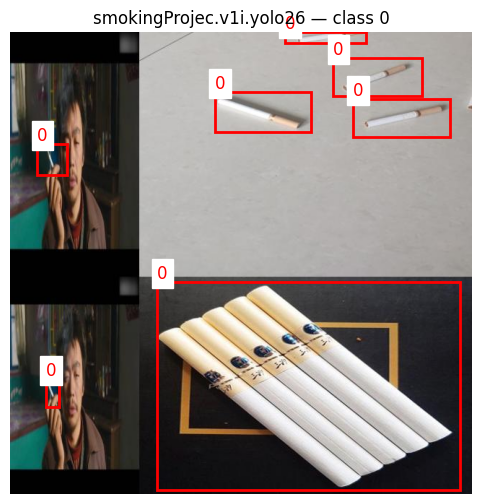


Dataset: VNTU_Object_Detection_YOLO8S.v8i.yolo26


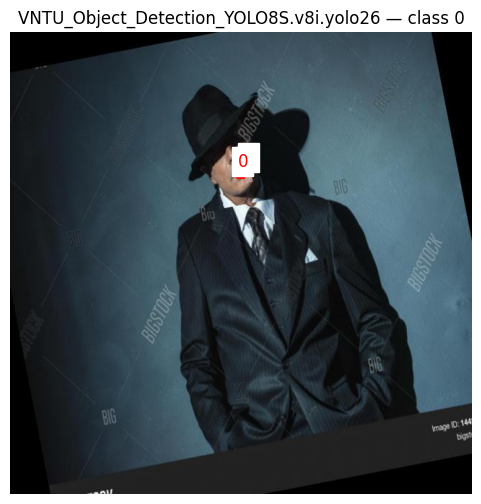

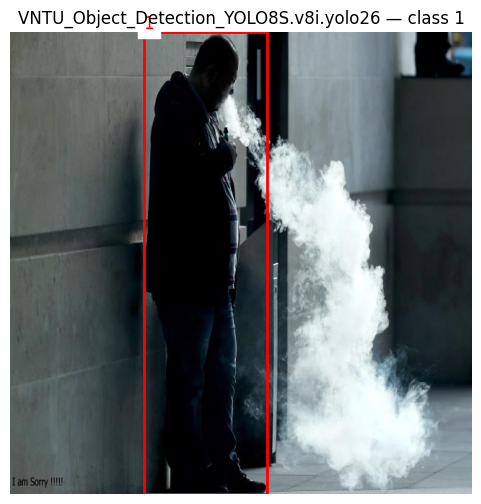

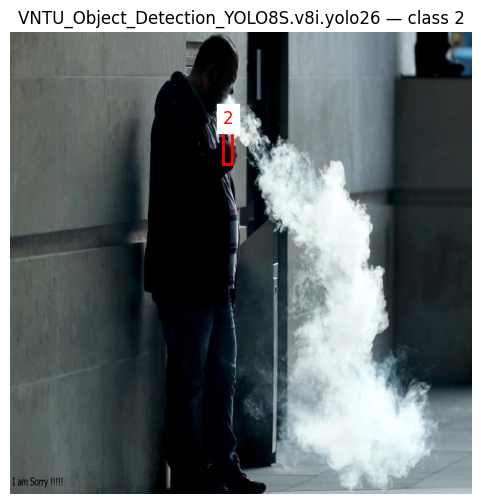

In [122]:
visualize_classes_per_dataset(df_micro_boxes)

In [123]:
from collections import defaultdict

def dataset_to_classes(df):
    result = defaultdict(set)

    for _, row in df.iterrows():
        with open(row.txt_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 1:
                    continue
                cls = int(float(parts[0]))
                result[row.dataset].add(cls)

    return {k: sorted(v) for k, v in result.items()}

In [124]:
dataset_classes = dataset_to_classes(df_micro_boxes)

In [125]:
dataset_classes

{'augmented.v1i.yolo26': [0],
 'cigar.v2i.yolo26': [0, 1],
 'cigarette smokers.v5-rsd.yolo26': [0],
 'Cigarette Vape Detection.v14i.yolo26': [0, 1],
 'CigDet_dataset': [0],
 'data_kaggle_smoke_eat_drink_phone': [0, 3],
 'iuhgiu786.v1i.yolo26': [0, 1],
 'project11.v1i.yolo26': [0],
 'sigara deneme.v2i.yolo26': [0],
 'Smoking detection.v2i.yolo26': [0],
 'Smoking Detection.v5i.yolo26': [0],
 'Smoking v2.v1i.yolo26': [0],
 'smoking.v1-smoker1.yolo26': [0],
 'smoking26.v1i.yolo26': [1],
 'smokingProjec.v1i.yolo26': [0],
 'VNTU_Object_Detection_YOLO8S.v8i.yolo26': [0, 1, 2]}

In [126]:
smoking_labels =  {'augmented.v1i.yolo26': [0],
'cigar.v2i.yolo26': [0, 1],
'cigarette smokers.v5-rsd.yolo26': [0],
'Cigarette Vape Detection.v14i.yolo26': [0, 1],
'CigDet_dataset': [0],
'data_kaggle_smoke_eat_drink_phone': [0],
'iuhgiu786.v1i.yolo26': [0],
'project11.v1i.yolo26': [0],
'sigara deneme.v2i.yolo26': [0],
'Smoking detection.v2i.yolo26': [0],
'Smoking Detection.v5i.yolo26': [0],
'Smoking v2.v1i.yolo26': [0],
'smoking.v1-smoker1.yolo26': [0],
'smoking26.v1i.yolo26': [1],
'smokingProjec.v1i.yolo26': [0],
'VNTU_Object_Detection_YOLO8S.v8i.yolo26': [0, 2]}

In [127]:
from pathlib import Path
import shutil

def prepare_smoking_dataset(df, smoking_labels, src_root="data", dst_root="data_prepaired"):
    for _, row in df.iterrows():
        dataset = row.dataset
        allowed = set(smoking_labels.get(dataset, []))
        if not allowed:
            continue

        src_img = Path(row.image_path)
        src_txt = Path(row.txt_path)

        dst_img = Path(str(src_img).replace(src_root, dst_root, 1))
        dst_txt = Path(str(src_txt).replace(src_root, dst_root, 1))

        dst_img.parent.mkdir(parents=True, exist_ok=True)
        dst_txt.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(src_img, dst_img)

        new_lines = []
        with open(src_txt) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls = int(float(parts[0]))
                if cls in allowed:
                    new_lines.append("0 " + " ".join(parts[1:]))

        if new_lines:
            with open(dst_txt, "w") as f:
                f.write("\n".join(new_lines))

In [128]:
prepare_smoking_dataset(df_micro_boxes, smoking_labels)